In [20]:
import warnings
warnings.filterwarnings('ignore')


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report, 
                             confusion_matrix, precision_score, recall_score, 
                             f1_score, roc_auc_score, roc_curve)


In [22]:
df=pd.read_csv("D:\Machine Learning\Datasets\Cases\Wisconsin\BreastCancer.csv",index_col=0)

In [23]:
df

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign
...,...,...,...,...,...,...,...,...,...,...
1369821,10,10,10,10,5,10,10,10,7,Malignant
1371026,5,10,10,10,4,10,5,6,3,Malignant
1371920,5,1,1,1,2,1,3,2,1,Benign


In [24]:
le=LabelEncoder()
df['Class']=le.fit_transform(df['Class'])
X,y=df.drop('Class',axis=1),df['Class']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25,stratify=y)
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")


Training samples: 489, Test samples: 210


In [26]:
# 5. FEATURE SCALING (IMPORTANT FOR KNN!)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)


In [27]:
# 6. CREATE KNN MODEL
# ============================================
# Basic KNN Classifier
knn = KNeighborsClassifier(
    n_neighbors=5)

In [28]:
# 7. TRAIN THE MODEL
# ============================================
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [29]:
y_pred = knn.predict(X_test_scaled)
y_pred_proba = knn.predict_proba(X_test_scaled)

In [30]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9714


In [31]:
# 10. DETAILED EVALUATION METRICS
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))


=== Classification Report ===
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       138
           1       0.99      0.93      0.96        72

    accuracy                           0.97       210
   macro avg       0.98      0.96      0.97       210
weighted avg       0.97      0.97      0.97       210



In [32]:
print("\n=== Confusion Matrix ===")
cm = confusion_matrix(y_test, y_pred)
print(cm)


=== Confusion Matrix ===
[[137   1]
 [  5  67]]


In [33]:
# Other metrics
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
print(f"\nPrecision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")


Precision: 0.9718
Recall: 0.9714
F1-Score: 0.9712


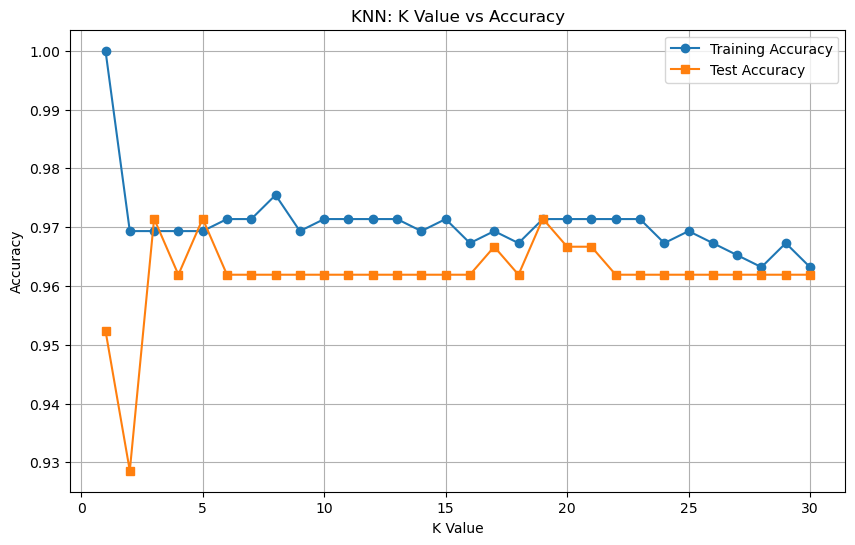

Optimal K value: 3


In [34]:
# 12. FINDING OPTIMAL K VALUE

k_values=range(1,31)
train_scores=[]
test_scores=[]

for k in k_values:
    knn_temp=KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled,y_train)
    train_scores.append(knn_temp.score(X_train_scaled, y_train))
    test_scores.append(knn_temp.score(X_test_scaled, y_test)) 

# Plot K vs Accuracy
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_scores, label='Training Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN: K Value vs Accuracy')
plt.legend()
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(test_scores)]
print(f"Optimal K value: {best_k}")

# HR


In [35]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder


hr=pd.read_csv("D:\Machine Learning\Datasets\HR_comma_sep.csv")
X , y = hr.drop('left',axis=1) , hr['left']
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.3,random_state=25,stratify=y)

In [36]:
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Training samples: 10496, Test samples: 4499


In [37]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

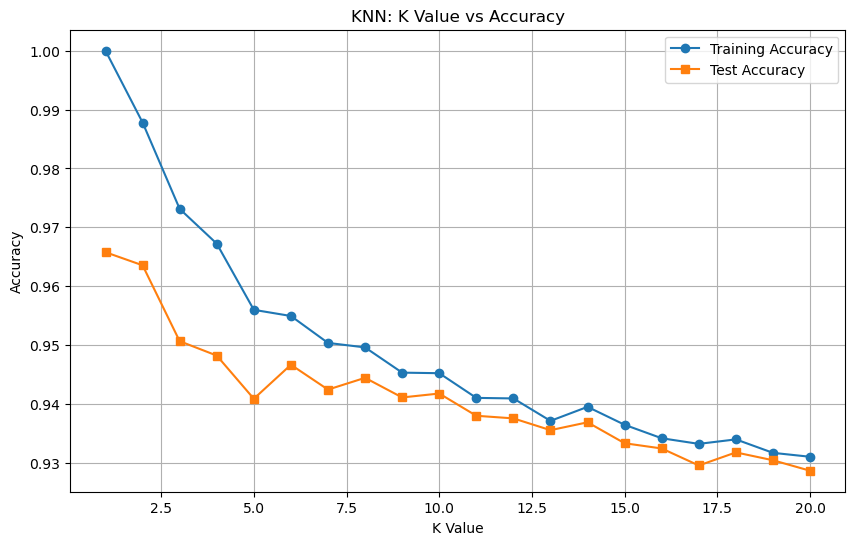

Optimal K value: 1


In [38]:
k_values=range(1,21)
train_scores=[]
test_scores=[]
for k in k_values:
    knn_temp=KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled,y_train)
    train_scores.append(knn_temp.score(X_train_scaled,y_train))
    
    test_scores.append(knn_temp.score(X_test_scaled,y_test))

# Plot K vs Accuracy
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_scores, label='Training Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN: K Value vs Accuracy')
plt.legend()
plt.grid(True)
plt.show()

best_k=k_values[np.argmax(test_scores)]
print(f"Optimal K value: {best_k}")